In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


In [3]:
df = pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/train.csv'
)

In [4]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Find CSV files attached to this Kaggle notebook
csv_files = glob.glob("/kaggle/input/**/*.csv", recursive=True)

print("CSV files found:")
for path in csv_files:
    print(path)

if not csv_files:
    raise FileNotFoundError(
        "No CSV files found. Add your dataset using Kaggle's Add Input."
    )

# Select the first CSV containing the satisfaction target.
# This avoids accidentally loading an unlabeled test.csv.
train_path = None

for path in csv_files:
    try:
        columns = pd.read_csv(path, nrows=0).columns.tolist()
        if "satisfaction" in columns:
            train_path = path
            break
    except Exception:
        continue

if train_path is None:
    raise ValueError(
        "Could not find a CSV with a 'satisfaction' column. "
        "Check the printed paths and column names."
    )

train_df = pd.read_csv(train_path)

print("\nSelected dataset:", train_path)
print("Dataset shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())

display(train_df.head())

CSV files found:
/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv

Selected dataset: /kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
Dataset shape: (299844, 2)
Columns: ['id', 'satisfaction']


,id,satisfaction
0,699635,0.443573
1,699636,0.443573
2,699637,0.443573
3,699638,0.443573
4,699639,0.443573


In [9]:
print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(
    df.isna().sum()
       .sort_values(ascending=False)
       .to_frame("missing_count")
       .query("missing_count > 0")
)

print("\nTarget distribution:")
print(df["satisfaction"].value_counts(dropna=False))

print("\nTarget proportions:")
print(df["satisfaction"].value_counts(normalize=True, dropna=False))

print("\nExact duplicate rows:", df.duplicated().sum())

Dataset shape: (699635, 23)

Data types:
id                                     int64
Age                                    int64
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online booking                 int64
Gate location                          int64
Food and drink                         int64
Online boarding                        int64
Seat comfort                           int64
Inflight entertainment                 int64
On-board service                       int64
Leg room service                       int64
Baggage handling                       int64
Checkin service                        int64
Cleanliness                            int64
Departure Delay in Minutes             int64
Arrival Delay in Minutes             float64
Gender                                object
Customer Type                         object
Type of Travel                        object
Class         

,missing_count
Arrival Delay in Minutes,292



Target distribution:
satisfaction
False    389296
True     310339
Name: count, dtype: int64

Target proportions:
satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

Exact duplicate rows: 0


In [10]:
ordinal_candidates = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness",
]

ordinal_features = [
    col for col in ordinal_candidates
    if col in df.columns
]

print("Ordinal features found:", len(ordinal_features))
print(ordinal_features)

for col in ordinal_features:
    print(f"\n{col}")
    print(sorted(df[col].dropna().unique().tolist()))

Ordinal features found: 13
['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']

Inflight wifi service
[0, 1, 2, 3, 4, 5]

Departure/Arrival time convenient
[0, 1, 2, 3, 4, 5]

Ease of Online booking
[0, 1, 2, 3, 4, 5]

Gate location
[0, 1, 2, 3, 4, 5]

Food and drink
[0, 1, 2, 3, 4, 5]

Online boarding
[0, 1, 2, 3, 4, 5]

Seat comfort
[0, 1, 2, 3, 4, 5]

Inflight entertainment
[0, 1, 2, 3, 4, 5]

On-board service
[0, 1, 2, 3, 4, 5]

Leg room service
[0, 1, 2, 3, 4, 5]

Baggage handling
[1, 2, 3, 4, 5]

Checkin service
[0, 1, 2, 3, 4, 5]

Cleanliness
[0, 1, 2, 3, 4, 5]


In [11]:
# STEP 5: Define ordinal rating encodings

encoding_maps = {
    "original": {
        0: 0, 1: 1, 2: 2, 3: 3, 4: 4, 5: 5
    },
    "mild": {
        0: 0, 1: 1, 2: 2.2, 3: 3.6, 4: 5.2, 5: 7
    },
    "strong": {
        0: 0, 1: 1, 2: 2, 3: 4, 4: 7, 5: 11
    },
    "exponential": {
        0: 0, 1: 1, 2: 2, 3: 4, 4: 8, 5: 16
    }
}

# Baggage handling has categories 1–5.
baggage_maps = {
    "original": {
        1: 1, 2: 2, 3: 3, 4: 4, 5: 5
    },
    "mild": {
        1: 1, 2: 2, 3: 3.2, 4: 4.6, 5: 6.2
    },
    "strong": {
        1: 1, 2: 2, 3: 3, 4: 5, 5: 8
    },
    "exponential": {
        1: 1, 2: 2, 3: 3, 4: 5, 5: 9
    }
}

# Check that every observed value has a mapping.
for col in ordinal_features:
    observed = set(df[col].dropna().unique())

    if col == "Baggage handling":
        valid_values = set(baggage_maps["original"])
    else:
        valid_values = set(encoding_maps["original"])

    assert observed.issubset(valid_values), (
        f"Unexpected values in {col}: {observed - valid_values}"
    )

print("All observed ordinal values have valid mappings.")

All observed ordinal values have valid mappings.


In [12]:
# STEP 6: Create one dataset per encoding

encoded_datasets = {}

for encoding_name in encoding_maps:
    encoded_df = df.copy()

    for col in ordinal_features:
        if col == "Baggage handling":
            mapping = baggage_maps[encoding_name]
        else:
            mapping = encoding_maps[encoding_name]

        encoded_df[col] = encoded_df[col].map(mapping)

    encoded_datasets[encoding_name] = encoded_df

# Inspect one feature under every encoding.
example_feature = "Inflight wifi service"

comparison = pd.DataFrame({
    name: data[example_feature].value_counts().sort_index()
    for name, data in encoded_datasets.items()
}).fillna(0)

print("Encoding comparison for:", example_feature)
display(comparison)

Encoding comparison for: Inflight wifi service


,original,mild,strong,exponential
Inflight wifi service,,,,
0.0,13102.0,13102.0,13102.0,13102.0
1.0,107739.0,107739.0,107739.0,107739.0
2.0,186870.0,0.0,186870.0,186870.0
2.2,0.0,186870.0,0.0,0.0
3.0,184436.0,0.0,0.0,0.0
3.6,0.0,184436.0,0.0,0.0
4.0,128136.0,0.0,184436.0,184436.0
5.0,79352.0,0.0,0.0,0.0
5.2,0.0,128136.0,0.0,0.0


In [13]:
from sklearn.model_selection import train_test_split

TARGET = "satisfaction"

# Remove the target and any ID-like columns from predictors.
id_columns = [
    col for col in df.columns
    if col.strip().lower() in {"id", "passengerid", "passenger_id"}
]

feature_columns = [
    col for col in df.columns
    if col != TARGET and col not in id_columns
]

X_original = df[feature_columns].copy()
y = df[TARGET].copy()

print("Feature matrix:", X_original.shape)
print("Target:", y.shape)
print("ID columns excluded:", id_columns)
print("Target classes:", y.unique())

Feature matrix: (699635, 21)
Target: (699635,)
ID columns excluded: ['id']
Target classes: [False  True]


In [14]:
from sklearn.model_selection import train_test_split

SPLIT_SEEDS = [42, 123, 2025, 7, 99]

splits = []

for seed in SPLIT_SEEDS:
    # First separate the test portion.
    X_train_val, X_test, y_train_val, y_test = train_test_split(
        X_original,
        y,
        test_size=0.20,
        random_state=seed,
        stratify=y
    )

    # Then separate validation from training.
    X_train, X_valid, y_train, y_valid = train_test_split(
        X_train_val,
        y_train_val,
        test_size=0.20,
        random_state=seed + 1,
        stratify=y_train_val
    )

    splits.append({
        "seed": seed,
        "train_idx": X_train.index,
        "valid_idx": X_valid.index,
        "test_idx": X_test.index
    })

    print(
        f"Seed {seed}: "
        f"train={len(X_train)}, "
        f"validation={len(X_valid)}, "
        f"test={len(X_test)}"
    )

Seed 42: train=447766, validation=111942, test=139927
Seed 123: train=447766, validation=111942, test=139927
Seed 2025: train=447766, validation=111942, test=139927
Seed 7: train=447766, validation=111942, test=139927
Seed 99: train=447766, validation=111942, test=139927


In [15]:
categorical_features = X_original.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Ordinal features must be treated as numeric for this experiment.
for col in ordinal_features:
    if col in categorical_features:
        categorical_features.remove(col)
    if col not in numerical_features:
        numerical_features.append(col)

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)

Categorical features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']
Numerical features: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']


In [17]:
from pathlib import Path
import pandas as pd

print("Current dataframe:")
print("df shape:", df.shape)

print("\n" + "=" * 80)
print("CSV FILES AVAILABLE IN /kaggle/input")
print("=" * 80)

csv_files = list(Path("/kaggle/input").rglob("*.csv"))

for i, path in enumerate(csv_files):
    try:
        temp = pd.read_csv(path)

        print(f"\n[{i}] {path}")
        print("    Shape:", temp.shape)
        print("    Columns:", temp.columns.tolist())

    except Exception as e:
        print(f"\n[{i}] {path}")
        print("    ERROR:", e)

Current dataframe:
df shape: (699635, 23)

CSV FILES AVAILABLE IN /kaggle/input

[0] /kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
    Shape: (299844, 2)
    Columns: ['id', 'satisfaction']

[1] /kaggle/input/competitions/playground-series-s6e10/train.csv
    Shape: (699635, 23)
    Columns: ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

[2] /kaggle/input/competitions/playground-series-s6e10/test.csv
    Shape: (299844, 22)
    Columns: ['id', 'Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', '

In [18]:
print("Dataset shape:", df.shape)

print("\nTarget distribution:")
print(df["satisfaction"].value_counts(normalize=True))

print("\nOrdinal features:")
print(ordinal_features)

print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset shape: (699635, 23)

Target distribution:
satisfaction
False    0.556427
True     0.443573
Name: proportion, dtype: float64

Ordinal features:
['Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness']

Missing values:
Arrival Delay in Minutes    292
dtype: int64


In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder
)
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

print("Libraries imported successfully!")
print("Dataset:", df.shape)
print("Encodings:", list(encoded_datasets.keys()))
print("Number of ordinal features:", len(ordinal_features))
print("Number of repeated splits:", len(splits))

Libraries imported successfully!
Dataset: (699635, 23)
Encodings: ['original', 'mild', 'strong', 'exponential']
Number of ordinal features: 13
Number of repeated splits: 5


In [21]:
TARGET = "satisfaction"

# Encode the target as 0 and 1.
target_encoder = LabelEncoder()
y = pd.Series(
    target_encoder.fit_transform(df[TARGET]),
    index=df.index,
    name=TARGET
)

print("Target mapping:")
print(dict(zip(target_encoder.classes_, target_encoder.transform(target_encoder.classes_))))

# Exclude target and identifier columns.
id_columns = [
    col for col in df.columns
    if col.strip().lower() in {"id", "passengerid", "passenger_id"}
]

feature_columns = [
    col for col in df.columns
    if col != TARGET and col not in id_columns
]

# Infer categorical and numerical columns.
categorical_features = [
    col for col in feature_columns
    if (
        pd.api.types.is_object_dtype(df[col])
        or isinstance(df[col].dtype, pd.CategoricalDtype)
        or pd.api.types.is_bool_dtype(df[col])
    )
]

numeric_features = [
    col for col in feature_columns
    if col not in categorical_features
]

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Target mapping:
{np.False_: np.int64(0), np.True_: np.int64(1)}
Numeric features: 17
Categorical features: 4


In [22]:
def build_pipeline(model_name, seed=42):

    scale_numeric = model_name in {
        "Logistic Regression",
        "Linear SVM"
    }

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    if model_name == "Majority baseline":
        model = DummyClassifier(strategy="most_frequent")

    elif model_name == "Logistic Regression":
        model = LogisticRegression(
            C=1.0,
            max_iter=300,
            solver="lbfgs"
        )

    elif model_name == "Linear SVM":
        # Calibration gives us probabilities for the same passengers.
        svm = LinearSVC(
            C=1.0,
            dual="auto",
            max_iter=2000,
            random_state=seed
        )

        model = CalibratedClassifierCV(
            estimator=svm,
            method="sigmoid",
            cv=2
        )

    elif model_name == "Decision Tree":
        model = DecisionTreeClassifier(
            max_depth=15,
            min_samples_leaf=20,
            random_state=seed
        )

    elif model_name == "Random Forest":
        model = RandomForestClassifier(
            n_estimators=100,
            max_depth=20,
            min_samples_leaf=10,
            max_features="sqrt",
            n_jobs=-1,
            random_state=seed
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])


model_names = [
    "Majority baseline",
    "Logistic Regression",
    "Linear SVM",
    "Decision Tree",
    "Random Forest"
]

print("Models:", model_names)

Models: ['Majority baseline', 'Logistic Regression', 'Linear SVM', 'Decision Tree', 'Random Forest']


In [23]:
# Pilot: original encoding, first split, Logistic Regression.
pilot_split = splits[0]
pilot_data = encoded_datasets["original"]

X_pilot_train = pilot_data.loc[
    pilot_split["train_idx"].union(pilot_split["valid_idx"]),
    feature_columns
]
y_pilot_train = y.loc[X_pilot_train.index]

X_pilot_test = pilot_data.loc[
    pilot_split["test_idx"],
    feature_columns
]
y_pilot_test = y.loc[X_pilot_test.index]

pilot_model = build_pipeline(
    "Logistic Regression",
    seed=pilot_split["seed"]
)

pilot_model.fit(X_pilot_train, y_pilot_train)

pilot_prob = pilot_model.predict_proba(X_pilot_test)[:, 1]
pilot_pred = (pilot_prob >= 0.5).astype(int)

print("Pilot ROC-AUC:", round(
    roc_auc_score(y_pilot_test, pilot_prob), 5
))
print("Pilot balanced accuracy:", round(
    balanced_accuracy_score(y_pilot_test, pilot_pred), 5
))

Pilot ROC-AUC: 0.92046
Pilot balanced accuracy: 0.87485


In [24]:
encoding_names = list(encoded_datasets.keys())

results = []
prediction_records = []

for split_number, split in enumerate(splits, start=1):

    print(f"\n========== Split {split_number}/{len(splits)} ==========")

    # Train on train + validation; test is held out.
    train_indices = split["train_idx"].union(split["valid_idx"])
    test_indices = split["test_idx"]

    y_train = y.loc[train_indices]
    y_test = y.loc[test_indices]

    for encoding_name in encoding_names:

        encoded_df = encoded_datasets[encoding_name]

        X_train = encoded_df.loc[train_indices, feature_columns]
        X_test = encoded_df.loc[test_indices, feature_columns]

        for model_name in model_names:

            print(f"Split {split_number} | {encoding_name} | {model_name}")

            model = build_pipeline(
                model_name,
                seed=split["seed"]
            )

            model.fit(X_train, y_train)

            probabilities = model.predict_proba(X_test)[:, 1]
            predictions = (probabilities >= 0.5).astype(int)

            auc = roc_auc_score(y_test, probabilities)
            balanced_acc = balanced_accuracy_score(
                y_test, predictions
            )

            results.append({
                "split": split_number,
                "seed": split["seed"],
                "encoding": encoding_name,
                "model": model_name,
                "roc_auc": auc,
                "balanced_accuracy": balanced_acc
            })

            prediction_records.append(pd.DataFrame({
                "row_index": test_indices,
                "split": split_number,
                "encoding": encoding_name,
                "model": model_name,
                "y_true": y_test.to_numpy(),
                "probability": probabilities,
                "prediction": predictions
            }))

results_df = pd.DataFrame(results)
predictions_df = pd.concat(
    prediction_records,
    ignore_index=True
)

print("\nExperiment finished!")
print("Metric rows:", len(results_df))
print("Prediction rows:", len(predictions_df))

display(results_df.head())


========== Split 1/5 ==========
Split 1 | original | Majority baseline
Split 1 | original | Logistic Regression
Split 1 | original | Linear SVM
Split 1 | original | Decision Tree
Split 1 | original | Random Forest
Split 1 | mild | Majority baseline
Split 1 | mild | Logistic Regression
Split 1 | mild | Linear SVM
Split 1 | mild | Decision Tree
Split 1 | mild | Random Forest
Split 1 | strong | Majority baseline
Split 1 | strong | Logistic Regression
Split 1 | strong | Linear SVM
Split 1 | strong | Decision Tree
Split 1 | strong | Random Forest
Split 1 | exponential | Majority baseline
Split 1 | exponential | Logistic Regression
Split 1 | exponential | Linear SVM
Split 1 | exponential | Decision Tree
Split 1 | exponential | Random Forest

========== Split 2/5 ==========
Split 2 | original | Majority baseline
Split 2 | original | Logistic Regression
Split 2 | original | Linear SVM
Split 2 | original | Decision Tree
Split 2 | original | Random Forest
Split 2 | mild | Majority baseline
Spli

,split,seed,encoding,model,roc_auc,balanced_accuracy
0,1,42,original,Majority baseline,0.500000,0.500000
1,1,42,original,Logistic Regression,0.920455,0.874855
2,1,42,original,Linear SVM,0.919613,0.873210
3,1,42,original,Decision Tree,0.951497,0.918084
4,1,42,original,Random Forest,0.956220,0.921354


In [25]:
summary = (
    results_df
    .groupby(["model", "encoding"])
    .agg(
        auc_mean=("roc_auc", "mean"),
        auc_std=("roc_auc", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_std=("balanced_accuracy", "std")
    )
    .reset_index()
)

display(
    summary.sort_values(
        ["model", "encoding"]
    ).round(5)
)

,model,encoding,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std
0,Decision Tree,exponential,0.95252,0.00074,0.91881,0.00053
1,Decision Tree,mild,0.95252,0.00074,0.91881,0.00053
2,Decision Tree,original,0.95252,0.00074,0.91881,0.00053
3,Decision Tree,strong,0.95252,0.00074,0.91881,0.00053
4,Linear SVM,exponential,0.93240,0.00081,0.89121,0.00111
5,Linear SVM,mild,0.92471,0.00080,0.87922,0.00093
6,Linear SVM,original,0.92074,0.00077,0.87377,0.00077
7,Linear SVM,strong,0.93022,0.00083,0.88768,0.00098
8,Logistic Regression,exponential,0.93282,0.00082,0.89176,0.00123
9,Logistic Regression,mild,0.92538,0.00082,0.88070,0.00087


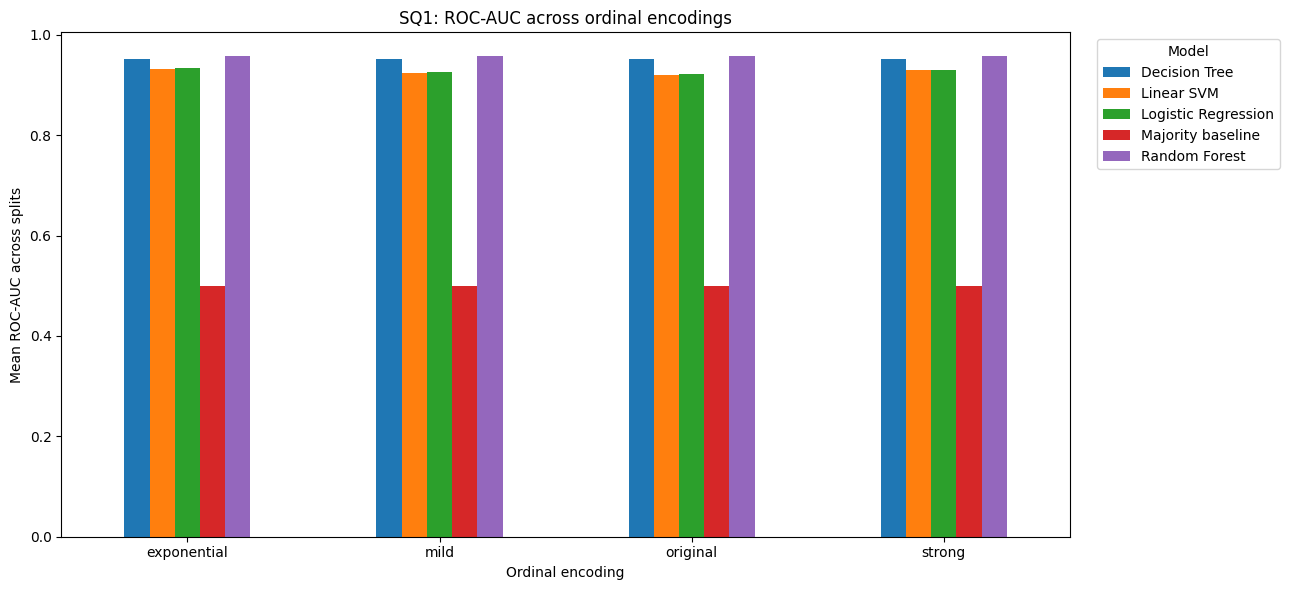

In [26]:
auc_table = summary.pivot(
    index="encoding",
    columns="model",
    values="auc_mean"
)

ax = auc_table.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set_title("SQ1: ROC-AUC across ordinal encodings")
ax.set_xlabel("Ordinal encoding")
ax.set_ylabel("Mean ROC-AUC across splits")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [27]:
comparison_rows = []

for model_name in model_names:
    for split_number in sorted(predictions_df["split"].unique()):

        part = predictions_df[
            (predictions_df["model"] == model_name) &
            (predictions_df["split"] == split_number)
        ]

        original = (
            part[part["encoding"] == "original"]
            .set_index("row_index")
            .sort_index()
        )

        for encoding_name in encoding_names:
            if encoding_name == "original":
                continue

            transformed = (
                part[part["encoding"] == encoding_name]
                .set_index("row_index")
                .sort_index()
            )

            # Ensure identical test passengers and ordering.
            transformed = transformed.loc[original.index]

            p0 = original["probability"].to_numpy()
            p1 = transformed["probability"].to_numpy()

            pred0 = original["prediction"].to_numpy()
            pred1 = transformed["prediction"].to_numpy()

            comparison_rows.append({
                "split": split_number,
                "model": model_name,
                "encoding": encoding_name,
                "mean_absolute_probability_change": np.mean(
                    np.abs(p1 - p0)
                ),
                "mean_signed_probability_change": np.mean(p1 - p0),
                "prediction_flip_rate": np.mean(pred1 != pred0)
            })

comparison_df = pd.DataFrame(comparison_rows)

comparison_summary = (
    comparison_df
    .groupby(["model", "encoding"])
    .agg(
        mean_probability_change=(
            "mean_absolute_probability_change", "mean"
        ),
        probability_change_std=(
            "mean_absolute_probability_change", "std"
        ),
        mean_signed_change=(
            "mean_signed_probability_change", "mean"
        ),
        prediction_flip_rate=(
            "prediction_flip_rate", "mean"
        )
    )
    .reset_index()
)

display(comparison_summary.round(6))

,model,encoding,mean_probability_change,probability_change_std,mean_signed_change,prediction_flip_rate
0,Decision Tree,exponential,0.000000,0.000000,0.000000,0.000000
1,Decision Tree,mild,0.000000,0.000000,0.000000,0.000000
2,Decision Tree,strong,0.000000,0.000000,0.000000,0.000000
3,Linear SVM,exponential,0.047514,0.000128,0.000069,0.035551
4,Linear SVM,mild,0.012724,0.000035,0.000023,0.010284
5,Linear SVM,strong,0.033006,0.000090,0.000056,0.026182
6,Logistic Regression,exponential,0.046697,0.000120,0.000024,0.033922
7,Logistic Regression,mild,0.012285,0.000026,0.000012,0.009692
8,Logistic Regression,strong,0.031895,0.000084,-0.000008,0.024544
9,Majority baseline,exponential,0.000000,0.000000,0.000000,0.000000


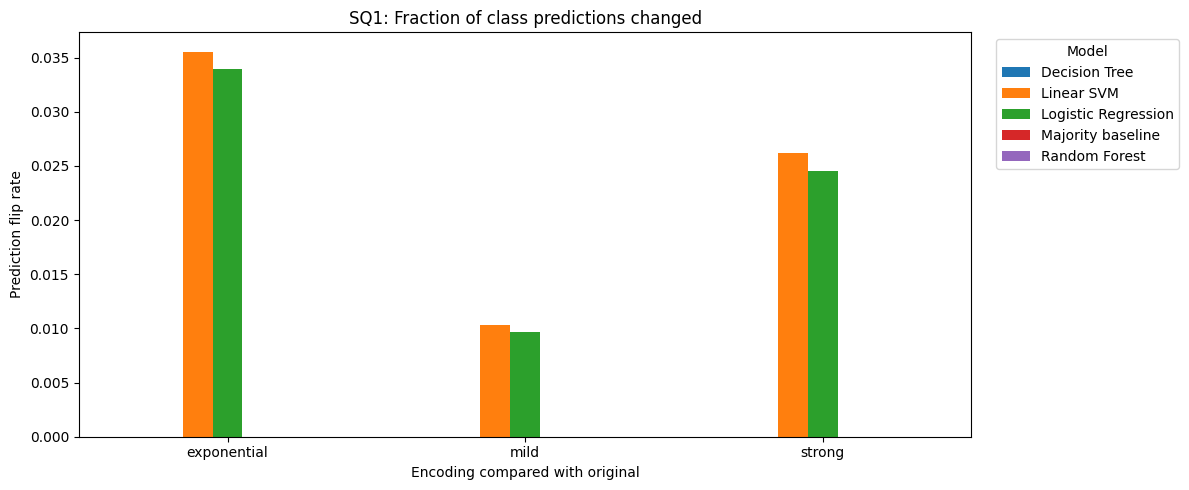

In [28]:
flip_table = comparison_summary.pivot(
    index="encoding",
    columns="model",
    values="prediction_flip_rate"
)

ax = flip_table.plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_title("SQ1: Fraction of class predictions changed")
ax.set_xlabel("Encoding compared with original")
ax.set_ylabel("Prediction flip rate")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [29]:
# Compare each transformed encoding with original
auc_wide = results_df.pivot(
    index=["split", "model"],
    columns="encoding",
    values="roc_auc"
)

auc_changes = []

for (split, model), row in auc_wide.iterrows():
    for encoding in ["mild", "strong", "exponential"]:
        auc_changes.append({
            "split": split,
            "model": model,
            "encoding": encoding,
            "original_auc": row["original"],
            "transformed_auc": row[encoding],
            "auc_change": row[encoding] - row["original"]
        })

auc_changes_df = pd.DataFrame(auc_changes)

auc_change_summary = (
    auc_changes_df
    .groupby(["model", "encoding"])
    .agg(
        mean_auc_change=("auc_change", "mean"),
        std_auc_change=("auc_change", "std"),
        min_auc_change=("auc_change", "min"),
        max_auc_change=("auc_change", "max")
    )
    .reset_index()
)

display(auc_change_summary.round(6))

,model,encoding,mean_auc_change,std_auc_change,min_auc_change,max_auc_change
0,Decision Tree,exponential,0.000000,0.000000,0.000000,0.000000
1,Decision Tree,mild,0.000000,0.000000,0.000000,0.000000
2,Decision Tree,strong,0.000000,0.000000,0.000000,0.000000
3,Linear SVM,exponential,0.011666,0.000261,0.011413,0.012025
4,Linear SVM,mild,0.003972,0.000084,0.003895,0.004064
5,Linear SVM,strong,0.009482,0.000199,0.009301,0.009703
6,Logistic Regression,exponential,0.011181,0.000237,0.010938,0.011495
7,Logistic Regression,mild,0.003737,0.000079,0.003657,0.003825
8,Logistic Regression,strong,0.009019,0.000183,0.008831,0.009226
9,Majority baseline,exponential,0.000000,0.000000,0.000000,0.000000


In [30]:
# Compare balanced accuracy against original encoding
ba_wide = results_df.pivot(
    index=["split", "model"],
    columns="encoding",
    values="balanced_accuracy"
)

ba_changes = []

for (split, model), row in ba_wide.iterrows():
    for encoding in ["mild", "strong", "exponential"]:
        ba_changes.append({
            "split": split,
            "model": model,
            "encoding": encoding,
            "balanced_accuracy_change":
                row[encoding] - row["original"]
        })

ba_changes_df = pd.DataFrame(ba_changes)

ba_summary = (
    ba_changes_df
    .groupby(["model", "encoding"])
    .agg(
        mean_change=("balanced_accuracy_change", "mean"),
        std_change=("balanced_accuracy_change", "std"),
        min_change=("balanced_accuracy_change", "min"),
        max_change=("balanced_accuracy_change", "max")
    )
    .reset_index()
)

display(ba_summary.round(6))

,model,encoding,mean_change,std_change,min_change,max_change
0,Decision Tree,exponential,0.000000,0.000000,0.000000,0.000000
1,Decision Tree,mild,0.000000,0.000000,0.000000,0.000000
2,Decision Tree,strong,0.000000,0.000000,0.000000,0.000000
3,Linear SVM,exponential,0.017444,0.000902,0.016196,0.018604
4,Linear SVM,mild,0.005454,0.000338,0.004908,0.005732
5,Linear SVM,strong,0.013915,0.000630,0.012944,0.014655
6,Logistic Regression,exponential,0.016178,0.000840,0.014909,0.017165
7,Logistic Regression,mild,0.005121,0.000251,0.004735,0.005369
8,Logistic Regression,strong,0.012860,0.000535,0.012024,0.013486
9,Majority baseline,exponential,0.000000,0.000000,0.000000,0.000000


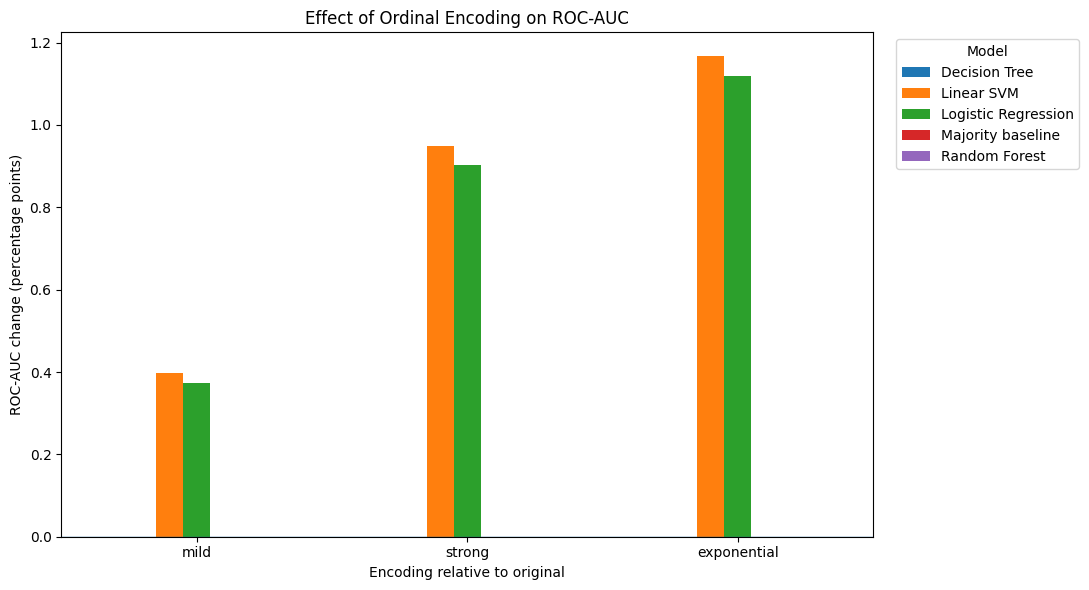

In [31]:
# Plot mean AUC change relative to original encoding
plot_df = auc_change_summary.pivot(
    index="encoding",
    columns="model",
    values="mean_auc_change"
)

plot_df = plot_df.reindex(["mild", "strong", "exponential"])

ax = (plot_df * 100).plot(
    kind="bar",
    figsize=(11, 6)
)

ax.axhline(0, linewidth=1)
ax.set_title("Effect of Ordinal Encoding on ROC-AUC")
ax.set_xlabel("Encoding relative to original")
ax.set_ylabel("ROC-AUC change (percentage points)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [32]:
# Verify every encoding preserves the order of observed rating levels.
for feature in ordinal_features:
    observed = sorted(df[feature].dropna().unique())

    print(f"\n{feature}")
    for encoding_name, encoded_df in encoded_datasets.items():
        transformed = encoded_df.loc[
            df[feature].dropna().index, feature
        ].to_numpy()

        original_values = df.loc[
            df[feature].dropna().index, feature
        ].to_numpy()

        pairs = sorted(set(zip(original_values, transformed)))
        mapped_values = [v for _, v in pairs]

        is_strict = all(
            mapped_values[i] < mapped_values[i + 1]
            for i in range(len(mapped_values) - 1)
        )

        print(f"  {encoding_name}: strictly increasing = {is_strict}")


Inflight wifi service
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing = True
  exponential: strictly increasing = True

Departure/Arrival time convenient
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing = True
  exponential: strictly increasing = True

Ease of Online booking
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing = True
  exponential: strictly increasing = True

Gate location
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing = True
  exponential: strictly increasing = True

Food and drink
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing = True
  exponential: strictly increasing = True

Online boarding
  original: strictly increasing = True
  mild: strictly increasing = True
  strong: strictly increasing =

In [33]:
# Audit the actual mapping for each ordinal feature.
for feature in ordinal_features:
    print(f"\n{feature}")

    audit = pd.DataFrame({
        "original": df[feature].dropna().unique()
    }).sort_values("original")

    for encoding_name, encoded_df in encoded_datasets.items():
        mapping = (
            encoded_df.loc[df[feature].dropna().index, feature]
            .groupby(df.loc[df[feature].dropna().index, feature])
            .first()
        )
        audit[encoding_name] = audit["original"].map(mapping)

    display(audit.reset_index(drop=True))


Inflight wifi service


,original,mild,strong,exponential
0,0,0.0,0,0
1,1,1.0,1,1
2,2,2.2,2,2
3,3,3.6,4,4
4,4,5.2,7,8
5,5,7.0,11,16



Departure/Arrival time convenient


,original,mild,strong,exponential
0,0,0.0,0,0
1,1,1.0,1,1
2,2,2.2,2,2
3,3,3.6,4,4
4,4,5.2,7,8
5,5,7.0,11,16



Ease of Online booking


,original,mild,strong,exponential
0,0,0.0,0,0
1,1,1.0,1,1
2,2,2.2,2,2
3,3,3.6,4,4
4,4,5.2,7,8
5,5,7.0,11,16


... (16 outputs left out)


Checkin service


,original,mild,strong,exponential
0,0,0.0,0,0
1,1,1.0,1,1
2,2,2.2,2,2
3,3,3.6,4,4
4,4,5.2,7,8
5,5,7.0,11,16



Cleanliness


,original,mild,strong,exponential
0,0,0.0,0,0
1,1,1.0,1,1
2,2,2.2,2,2
3,3,3.6,4,4
4,4,5.2,7,8
5,5,7.0,11,16


In [38]:
import time
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, balanced_accuracy_score

def build_linear_pipeline(model_name, use_scaling=True, seed=42):

    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if use_scaling:
        numeric_steps.append(("scaler", StandardScaler()))

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocess = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

    if model_name == "Logistic Regression":
        model = LogisticRegression(
            C=1.0,
            max_iter=1000,
            solver="lbfgs",
            tol=1e-4
        )

    elif model_name == "Linear SVM":
        # No probability calibration in this sensitivity experiment.
        model = LinearSVC(
            C=1.0,
            dual="auto",
            max_iter=3000,
            random_state=seed
        )

    else:
        raise ValueError("Unknown model.")

    return Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])

print("Fast sensitivity pipeline ready.")

Fast sensitivity pipeline ready.


In [ ]:
scaling_results = []
convergence_issues = []

start_time = time.time()

for split_number, split in enumerate(splits, start=1):

    train_indices = split["train_idx"].union(split["valid_idx"])
    test_indices = split["test_idx"]

    y_train = y.loc[train_indices]
    y_test = y.loc[test_indices]

    for encoding_name, encoded_df in encoded_datasets.items():

        X_train = encoded_df.loc[train_indices, feature_columns]
        X_test = encoded_df.loc[test_indices, feature_columns]

        for model_name in ["Logistic Regression", "Linear SVM"]:
            for use_scaling in [True, False]:

                condition = (
                    "standardized" if use_scaling
                    else "unstandardized"
                )

                label = (
                    f"Split {split_number}/5 | "
                    f"{encoding_name} | {model_name} | {condition}"
                )

                print(label, flush=True)

                model = build_linear_pipeline(
                    model_name,
                    use_scaling=use_scaling,
                    seed=split["seed"]
                )

                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter("always", ConvergenceWarning)

                    model.fit(X_train, y_train)

                for warning in caught:
                    if issubclass(warning.category, ConvergenceWarning):
                        convergence_issues.append({
                            "split": split_number,
                            "encoding": encoding_name,
                            "model": model_name,
                            "scaling": condition,
                            "warning": str(warning.message)
                        })

                fitted_model = model.named_steps["model"]

                # Logistic Regression iteration diagnostics
                iterations = int(np.max(fitted_model.n_iter_))

                # AUC uses probabilities for Logistic Regression
                # and decision scores for Linear SVM.
                if model_name == "Logistic Regression":
                    scores = model.predict_proba(X_test)[:, 1]
                else:
                    scores = model.decision_function(X_test)

                predictions = model.predict(X_test)

                scaling_results.append({
                    "split": split_number,
                    "model": model_name,
                    "encoding": encoding_name,
                    "scaling": condition,
                    "roc_auc": roc_auc_score(y_test, scores),
                    "balanced_accuracy": balanced_accuracy_score(
                        y_test, predictions
                    ),
                    "iterations": iterations
                })

    print(
        f"Completed split {split_number}/5 | "
        f"Elapsed: {(time.time() - start_time) / 60:.1f} minutes",
        flush=True
    )

scaling_df = pd.DataFrame(scaling_results)

print("\nExperiment finished.")
print(f"Total runtime: {(time.time() - start_time) / 60:.2f} minutes")
print("Convergence warnings:", len(convergence_issues))

display(scaling_df.head())

if convergence_issues:
    display(pd.DataFrame(convergence_issues))

Split 1/5 | original | Logistic Regression | standardized
Split 1/5 | original | Logistic Regression | unstandardized
Split 1/5 | original | Linear SVM | standardized
Split 1/5 | original | Linear SVM | unstandardized
Split 1/5 | mild | Logistic Regression | standardized
Split 1/5 | mild | Logistic Regression | unstandardized
Split 1/5 | mild | Linear SVM | standardized
Split 1/5 | mild | Linear SVM | unstandardized
Split 1/5 | strong | Logistic Regression | standardized
Split 1/5 | strong | Logistic Regression | unstandardized
Split 1/5 | strong | Linear SVM | standardized
Split 1/5 | strong | Linear SVM | unstandardized
Split 1/5 | exponential | Logistic Regression | standardized
Split 1/5 | exponential | Logistic Regression | unstandardized
Split 1/5 | exponential | Linear SVM | standardized
Split 1/5 | exponential | Linear SVM | unstandardized
Completed split 1/5 | Elapsed: 11.1 minutes
Split 2/5 | original | Logistic Regression | standardized
Split 2/5 | original | Logistic Regres

In [ ]:
scaling_summary = (
    scaling_df
    .groupby(["model", "encoding", "scaling"])
    .agg(
        auc_mean=("roc_auc", "mean"),
        auc_std=("roc_auc", "std"),
        balanced_accuracy_mean=("balanced_accuracy", "mean"),
        balanced_accuracy_std=("balanced_accuracy", "std"),
        max_iterations=("iterations", "max")
    )
    .reset_index()
)

display(scaling_summary.round(5))

In [ ]:
for model_name in linear_models:

    subset = scaling_summary[
        scaling_summary["model"] == model_name
    ]

    plot_data = subset.pivot(
        index="encoding",
        columns="scaling",
        values="auc_mean"
    ).reindex(["original", "mild", "strong", "exponential"])

    ax = plot_data.plot(
        kind="bar",
        figsize=(9, 5)
    )

    ax.set_title(f"{model_name}: Effect of Scaling on ROC-AUC")
    ax.set_xlabel("Ordinal encoding")
    ax.set_ylabel("Mean ROC-AUC across splits")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Scaling")
    plt.tight_layout()
    plt.show()